# Logistic regression: airline satisfaction

Split the labeled data into stratified training (80%) and validation (20%) subsets **before preprocessing**. Fit imputation, encoding, scaling, and the model on the training subset only. The separate unlabeled test file is not needed for validation.


In [7]:
from pathlib import Path
import sys

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, ConfusionMatrixDisplay

# Find the repo whether the notebook runs from src/ or the project root.
project_root = Path.cwd()
if project_root.name == "src":
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

from src.preprocessing import rating_cols, run_full_preprocessing


In [8]:
# Load the labeled data.
df = pd.read_csv(project_root / "data" / "train.csv")

# Features exclude the target and the passenger ID.
X = df.drop(columns=["satisfaction", "id"])

# The target is boolean: 0 = dissatisfied/neutral, 1 = satisfied.
y = df["satisfaction"].astype(int)

# Split BEFORE preprocessing to prevent validation data from affecting training.
# stratify=y keeps the same class proportions in both subsets.
# random_state=42 makes the split reproducible.
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Compare the percentage of each class after splitting.
print(pd.DataFrame({
    "Train (%)": y_train.value_counts(normalize=True) * 100,
    "Validation (%)": y_val.value_counts(normalize=True) * 100,
}).round(2))


              Train (%)  Validation (%)
satisfaction                           
0                 55.64           55.64
1                 44.36           44.36


## Preprocess the split data

Preserve zero-rating indicators and convert zero ratings to missing values, following the repository preprocessing notebook. Fill missing arrival delays with the training median, then call the repository module to impute ratings, encode categories, engineer features, and scale continuous features.


In [9]:
# Load test features and preserve their original row order.
test_df = pd.read_csv(project_root / "data" / "test.csv")
X_test = test_df[X.columns].copy()

# Copy the subsets so we can safely prepare their values.
X_train = X_train.copy()
X_val = X_val.copy()

# A zero service rating means "not rated".
# Keep an indicator, then replace zero with a missing value for imputation.
for data in [X_train, X_val, X_test]:
    for col in rating_cols:
        data[col + "_not_rated"] = (data[col] == 0).astype(int)
        data[col] = data[col].replace(0, float("nan"))

# Use only the training median to fill missing arrival delays in both subsets.
arrival_col = "Arrival Delay in Minutes"
arrival_median = X_train[arrival_col].median()
X_train[arrival_col] = X_train[arrival_col].fillna(arrival_median)
X_val[arrival_col] = X_val[arrival_col].fillna(arrival_median)
X_test[arrival_col] = X_test[arrival_col].fillna(arrival_median)

# The repo module encodes categories, imputes ratings, creates features,
# and scales numeric features. It fits preprocessing on training data only.
# Apply the same training-fitted preprocessing to validation and test data.
X_train_proc, X_val_proc, X_test_proc, scaler = run_full_preprocessing(
    X_train, X_val, X_test
)


## Evaluation metrics

The positive class is **satisfied (1)**; the negative class is **neutral or dissatisfied (0)**.

- **TP:** actually satisfied and predicted satisfied.
- **TN:** actually negative and predicted negative.
- **FP:** actually negative but predicted satisfied.
- **FN:** actually satisfied but predicted negative.

**Accuracy** measures the fraction of all predictions that are correct:

$$
\mathrm{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN}
$$

**Precision** measures how many passengers predicted satisfied are actually satisfied:

$$
\mathrm{Precision} = \frac{TP}{TP + FP}
$$

**Recall** measures how many actually satisfied passengers are predicted satisfied:

$$
\mathrm{Recall} = \frac{TP}{TP + FN}
$$


Accuracy: 0.8956
Precision (satisfied): 0.8855
Recall (satisfied): 0.8782


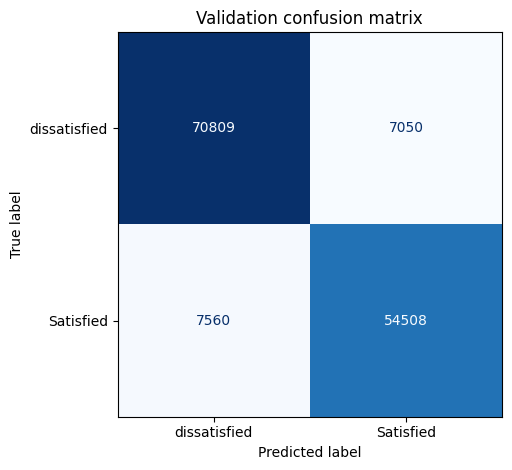

In [10]:
# Train logistic regression using the preprocessed training data.
model = LogisticRegression(max_iter=2000, random_state=42)
model.fit(X_train_proc, y_train)

# Predict validation classes: 0 = dissatisfied/neutral, 1 = satisfied.
y_pred = model.predict(X_val_proc)

# Treat satisfied (1) as the positive class for precision and recall.
print(f"Accuracy: {accuracy_score(y_val, y_pred):.4f}")
print(f"Precision (satisfied): {precision_score(y_val, y_pred, pos_label=1, zero_division=0):.4f}")
print(f"Recall (satisfied): {recall_score(y_val, y_pred, pos_label=1, zero_division=0):.4f}")

# Rows show actual classes; columns show predicted classes.
ConfusionMatrixDisplay.from_predictions(
    y_val, y_pred,
    labels=[0, 1],
    display_labels=["dissatisfied", "Satisfied"],
    cmap="Blues",
    values_format="d",
    colorbar=False,
)
plt.title("Validation confusion matrix")
plt.tight_layout()
plt.show()


## Predict test data and save the submission
Use the probability of satisfied (1), matching the sample submission format.


In [ ]:
# Predict satisfaction probabilities using the trained model.
positive_class = list(model.classes_).index(1)
test_probabilities = model.predict_proba(X_test_proc)[:, positive_class]

# Match the sample submission columns and ID order.
submission = pd.read_csv(project_root / "data" / "sample_submission.csv")
assert submission["id"].equals(test_df["id"]), "Test IDs do not match the submission template."
submission["satisfaction"] = test_probabilities

# Save without a pandas index column.
submission_dir = project_root / "submissions"
submission_dir.mkdir(exist_ok=True)
submission_path = submission_dir / "logistic_regression.csv"
submission.to_csv(submission_path, index=False)
print(f"Saved {len(submission):,} predictions to {submission_path}")
print(submission.head())


Saved 299,844 predictions to d:\college\Term 9\Data mining\airline-satisfaction\submisions\logistic_regression.csv
       id  satisfaction
0  699635      0.149149
1  699636      0.738630
2  699637      0.601246
3  699638      0.054062
4  699639      0.001091


## Results on kaggle
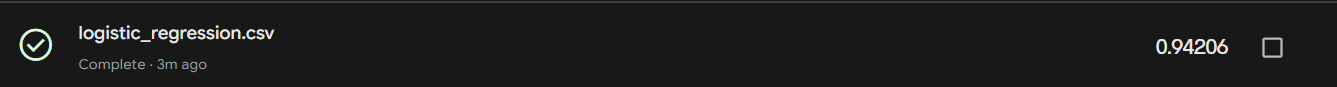